In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    normalized_mutual_info_score,
    adjusted_rand_score
)
from sklearn.decomposition import PCA

# --- Reproducibility Setup ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- Compute Device Selection (Apple Silicon MPS / CUDA / CPU) ---
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Active Compute Device: {device}")

# --- Directory Setup for Artifacts ---
ARTIFACT_DIR = "./customics_artifacts"
os.makedirs(os.path.join(ARTIFACT_DIR, "models"), exist_ok=True)
os.makedirs(os.path.join(ARTIFACT_DIR, "embeddings"), exist_ok=True)
print(f"Artifacts directory prepared at: {ARTIFACT_DIR}")
print("(64, 64,64)-.64*3->192->64")

Active Compute Device: mps
Artifacts directory prepared at: ./customics_artifacts
(64, 64,64)-.64*3->192->64


In [3]:
# Dataset directory
DATA_DIR = "Main_Dataset/Classification_datasets/Pan-cancer/Original"

print("Loading Pan-Cancer multi-omics data tables (8,314 patients)...")

# 1. Load the 3 core omics modalities
mrna_df = pd.read_csv(os.path.join(DATA_DIR, "Pan-cancer_mRNA.csv"), index_col=0)
methy_df = pd.read_csv(os.path.join(DATA_DIR, "Pan-cancer_Methy.csv"), index_col=0)
cnv_df = pd.read_csv(os.path.join(DATA_DIR, "Pan-cancer_CNV.csv"), index_col=0)

# 2. Load ground-truth cancer class labels
labels_df = pd.read_csv(os.path.join(DATA_DIR, "Pan-cancer_label_num.csv"))
label_col = labels_df.columns[-1]

# 3. Transpose matrices to (N_patients, N_features) and convert to float32 / int64
X_mrna = mrna_df.T.values.astype(np.float32)
X_methy = methy_df.T.values.astype(np.float32)
X_cnv = cnv_df.T.values.astype(np.float32)
y = labels_df[label_col].values.astype(np.int64)

# 4. Extract dataset dimensions
num_patients = len(y)
num_classes = len(np.unique(y))
mrna_dim = X_mrna.shape[1]
methy_dim = X_methy.shape[1]
cnv_dim = X_cnv.shape[1]

print(f"\nCohort Size        : {num_patients} Patients across {num_classes} Distinct Primary Cancer Types")
print(f"  * mRNA Features   : {mrna_dim}")
print(f"  * Methylation Probes: {methy_dim}")
print(f"  * CNV Features    : {cnv_dim}")

Loading Pan-Cancer multi-omics data tables (8,314 patients)...

Cohort Size        : 8314 Patients across 32 Distinct Primary Cancer Types
  * mRNA Features   : 3217
  * Methylation Probes: 3139
  * CNV Features    : 3105


In [ ]:
SUB_DIM = 64      # Sub-autoencoder bottleneck dimension per modality
CENTRAL_DIM = 64  # Central VAE bottleneck dimension

class SourceAutoencoder(nn.Module):
    def __init__(self, in_features, latent_dim=SUB_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, latent_dim),
            nn.BatchNorm1d(latent_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, in_features)
        )

    def forward(self, x):
        z = self.encoder(x)
        rec = self.decoder(z)
        return z, rec

def compute_mmd(z, z_prior):
    """Pairwise Euclidean formulation for native Apple Silicon MPS / CUDA backpropagation"""
    def pairwise_sq_dist(x, y):
        x_norm = (x**2).sum(dim=1, keepdim=True)
        y_norm = (y**2).sum(dim=1, keepdim=True).t()
        dist = x_norm + y_norm - 2.0 * torch.matmul(x, y.t())
        return torch.clamp(dist, min=0.0)

    def rbf_kernel(x, y, sigma=1.0):
        beta = 1.0 / (2.0 * sigma**2)
        dist = pairwise_sq_dist(x, y)
        return torch.exp(-beta * dist)

    k_zz = rbf_kernel(z, z)
    k_prior = rbf_kernel(z_prior, z_prior)
    k_cross = rbf_kernel(z, z_prior)
    return k_zz.mean() + k_prior.mean() - 2.0 * k_cross.mean()

class CustOmicsPanCancer(nn.Module):
    def __init__(self, mrna_dim, methy_dim, cnv_dim, num_classes):
        super().__init__()
        # Phase 1: Source-Specific Sub-Autoencoders
        self.ae_mrna = SourceAutoencoder(mrna_dim, SUB_DIM)
        self.ae_methy = SourceAutoencoder(methy_dim, SUB_DIM)
        self.ae_cnv = SourceAutoencoder(cnv_dim, SUB_DIM)

        # Phase 2: Central VAE
        fused_in_dim = SUB_DIM * 3
        self.central_encoder = nn.Sequential(
            nn.Linear(fused_in_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(128, CENTRAL_DIM)
        self.fc_logvar = nn.Linear(128, CENTRAL_DIM)

        self.central_decoder = nn.Sequential(
            nn.Linear(CENTRAL_DIM, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, fused_in_dim)
        )

        # Classification Head for 32 Cancer Classes
        self.classifier = nn.Sequential(
            nn.Linear(CENTRAL_DIM, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x_mrna, x_methy, x_cnv, phase=1):
        z_mrna, rec_mrna = self.ae_mrna(x_mrna)
        z_methy, rec_methy = self.ae_methy(x_methy)
        z_cnv, rec_cnv = self.ae_cnv(x_cnv)

        if phase == 1:
            return (rec_mrna, rec_methy, rec_cnv), None, None

#Phase 2 functionallity starts here
        fused_sub = torch.cat([z_mrna, z_methy, z_cnv], dim=1)
        h = self.central_encoder(fused_sub)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z_central = self.reparameterize(mu, logvar)

        rec_central = self.central_decoder(z_central)
        logits = self.classifier(mu)

        return (rec_mrna, rec_methy, rec_cnv), (rec_central, fused_sub, z_central), logits

    def extract_latent(self, x_mrna, x_methy, x_cnv):
        """Extract deterministic mean latent representation mu for downstream evaluation/clustering"""
        z_mrna, _ = self.ae_mrna(x_mrna)
        z_methy, _ = self.ae_methy(x_methy)
        z_cnv, _ = self.ae_cnv(x_cnv)
        fused_sub = torch.cat([z_mrna, z_methy, z_cnv], dim=1)
        h = self.central_encoder(fused_sub)
        return self.fc_mu(h)

print("Architecture and loss functions defined successfully.")

Architecture and loss functions defined successfully.


In [ ]:
# --- Training Configuration ---
MAX_PHASE1_EPOCHS = 100
MAX_PHASE2_EPOCHS = 100
MIN_PHASE2_EPOCHS = 50          # Guaranteed training threshold before early stopping can activate
EARLY_STOPPING_PATIENCE = 20    # Patience buffer for multi-objective loss stabilization
MIN_DELTA = 1e-4

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_metrics = []
all_per_class_reports = []

print("Executing CustOmics Pan-Cancer 5-Fold Cross-Validation (100 Phase 1 + 100 Phase 2 Epochs)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_mrna, y)):
    print(f"\n====================== FOLD {fold + 1} / 5 ======================")

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_mrna[train_idx], dtype=torch.float32),
            torch.tensor(X_methy[train_idx], dtype=torch.float32),
            torch.tensor(X_cnv[train_idx], dtype=torch.float32),
            torch.tensor(y[train_idx], dtype=torch.long)
        ),
        batch_size=64, shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_mrna[val_idx], dtype=torch.float32),
            torch.tensor(X_methy[val_idx], dtype=torch.float32),
            torch.tensor(X_cnv[val_idx], dtype=torch.float32),
            torch.tensor(y[val_idx], dtype=torch.long)
        ),
        batch_size=64, shuffle=False
    )

    model = CustOmicsPanCancer(X_mrna.shape[1], X_methy.shape[1], X_cnv.shape[1], num_classes).to(device)
    mse_loss = nn.MSELoss()
    ce_loss = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

    # ---------------- PHASE 1: Sub-AE Pre-training ----------------
    best_p1_loss = float('inf')
    p1_patience = 0

    print("--- Starting Phase 1 (Sub-Autoencoder Denoising) ---")
    for epoch in range(1, MAX_PHASE1_EPOCHS + 1):
        model.train()
        running_recon = 0.0
        for b_mrna, b_methy, b_cnv, _ in train_loader:
            b_mrna, b_methy, b_cnv = b_mrna.to(device), b_methy.to(device), b_cnv.to(device)
            optimizer.zero_grad()
            (r_mrna, r_methy, r_cnv), _, _ = model(b_mrna, b_methy, b_cnv, phase=1)
            loss = mse_loss(r_mrna, b_mrna) + mse_loss(r_methy, b_methy) + mse_loss(r_cnv, b_cnv)
            loss.backward()
            optimizer.step()
            running_recon += loss.item()

        avg_recon = running_recon / len(train_loader)
        if best_p1_loss - avg_recon > MIN_DELTA:
            best_p1_loss = avg_recon
            p1_patience = 0
        else:
            p1_patience += 1

        if epoch % 10 == 0 or epoch == MAX_PHASE1_EPOCHS:
            print(f"Phase 1 | Epoch {epoch:02d}/{MAX_PHASE1_EPOCHS} | Train Recon Loss: {avg_recon:.4f}")

    # ----- ----------- PHASE 2: Joint VAE + Classification ----------------
    best_val_loss = float('inf')
    best_model_state = None
    p2_patience = 0

    print("\n--- Starting Phase 2 (Central Fusion + Classification) ---")
    for epoch in range(1, MAX_PHASE2_EPOCHS + 1):
        model.train()
        r_recon, r_mmd, r_ce = 0.0, 0.0, 0.0

        for b_mrna, b_methy, b_cnv, b_y in train_loader:
            b_mrna, b_methy, b_cnv, b_y = b_mrna.to(device), b_methy.to(device), b_cnv.to(device), b_y.to(device)
            optimizer.zero_grad()
            (r_mrna, r_methy, r_cnv), (r_central, f_sub, z_c), logits = model(b_mrna, b_methy, b_cnv, phase=2)
            
            recon_loss = (mse_loss(r_mrna, b_mrna) + mse_loss(r_methy, b_methy) +
                          mse_loss(r_cnv, b_cnv) + mse_loss(r_central, f_sub.detach()))
            prior_z = torch.randn_like(z_c)
            mmd = compute_mmd(z_c, prior_z)
            cls_loss = ce_loss(logits, b_y)

            total_loss = recon_loss + (0.1 * mmd) + (2.0 * cls_loss)
            total_loss.backward()
            optimizer.step()

            r_recon += recon_loss.item()
            r_mmd += mmd.item()
            r_ce += cls_loss.item()

        # Validation Check for Early Stopping
        model.eval()
        val_loss = 0.0
        val_preds_ep, val_targets_ep = [], []
        with torch.no_grad():
            for b_mrna, b_methy, b_cnv, b_y in val_loader:
                b_mrna, b_methy, b_cnv, b_y = b_mrna.to(device), b_methy.to(device), b_cnv.to(device), b_y.to(device)
                (r_mrna, r_methy, r_cnv), (r_central, f_sub, z_c), logits = model(b_mrna, b_methy, b_cnv, phase=2)
                
                recon_loss = (mse_loss(r_mrna, b_mrna) + mse_loss(r_methy, b_methy) +
                              mse_loss(r_cnv, b_cnv) + mse_loss(r_central, f_sub.detach()))
                prior_z = torch.randn_like(z_c)
                mmd = compute_mmd(z_c, prior_z)
                cls_loss = ce_loss(logits, b_y)
                val_loss += (recon_loss + (0.1 * mmd) + (2.0 * cls_loss)).item()

                val_preds_ep.extend(logits.argmax(dim=1).cpu().numpy())
                val_targets_ep.extend(b_y.cpu().numpy())

        avg_val_loss = val_loss / len(val_loader)
        epoch_acc = accuracy_score(val_targets_ep, val_preds_ep)

        if best_val_loss - avg_val_loss > MIN_DELTA:
            best_val_loss = avg_val_loss
            best_model_state = model.state_dict().copy()
            p2_patience = 0
        else:
            p2_patience += 1

        if epoch % 10 == 0 or epoch >= MIN_PHASE2_EPOCHS:
            print(f"Phase 2 | Epoch {epoch:02d}/{MAX_PHASE2_EPOCHS} | Recon: {r_recon/len(train_loader):.4f} | MMD: {r_mmd/len(train_loader):.4f} | CE: {r_ce/len(train_loader):.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {epoch_acc*100:.2f}%")

        # Controlled early stopping condition
        if epoch >= MIN_PHASE2_EPOCHS and p2_patience >= EARLY_STOPPING_PATIENCE:
            print(f"Phase 2 reached convergence stopping threshold at epoch {epoch}.")
            break

    # Restore best checkpoint weights
    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    # ---------------- Final Evaluation for this Fold ----------------
    model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for b_mrna, b_methy, b_cnv, b_y in val_loader:
            b_mrna, b_methy, b_cnv = b_mrna.to(device), b_methy.to(device), b_cnv.to(device)
            _, _, logits = model(b_mrna, b_methy, b_cnv, phase=2)
            val_preds.extend(logits.argmax(dim=1).cpu().numpy())
            val_targets.extend(b_y.numpy())

    acc = accuracy_score(val_targets, val_preds)
    prec = precision_score(val_targets, val_preds, average="macro", zero_division=0)
    rec = recall_score(val_targets, val_preds, average="macro", zero_division=0)
    f1 = f1_score(val_targets, val_preds, average="macro", zero_division=0)
    nmi = normalized_mutual_info_score(val_targets, val_preds)
    ari = adjusted_rand_score(val_targets, val_preds)

    print(f"\nFold {fold + 1} Result -> Acc: {acc:.4f} | Prec: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f} | NMI: {nmi:.4f} | ARI: {ari:.4f}")

    # Generate Per-Class Precision, Recall, and F1 Report
    report_dict = classification_report(val_targets, val_preds, output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report_dict).transpose()
    report_df["fold"] = fold + 1
    all_per_class_reports.append(report_df)

    # Save Model Checkpoint
    torch.save(model.state_dict(), os.path.join(ARTIFACT_DIR, "models", f"pancancer_model_fold_{fold+1}.pt"))

    # Extract & Save Full Latent Representation for Downstream PCA
    with torch.no_grad():
        latent_matrix = model.extract_latent(
            torch.tensor(X_mrna, dtype=torch.float32).to(device),
            torch.tensor(X_methy, dtype=torch.float32).to(device),
            torch.tensor(X_cnv, dtype=torch.float32).to(device)
        ).cpu().numpy()
    np.save(os.path.join(ARTIFACT_DIR, "embeddings", f"latent_fold_{fold+1}.npy"), latent_matrix)

    fold_metrics.append({
        "fold": fold + 1, "accuracy": acc, "precision": prec,
        "recall": rec, "f1_macro": f1, "nmi": nmi, "ari": ari
    })

# Save Aggregated Tables
results_df = pd.DataFrame(fold_metrics)
results_df.to_csv(os.path.join(ARTIFACT_DIR, "pancancer_benchmark_results.csv"), index=False)
pd.concat(all_per_class_reports).to_csv(os.path.join(ARTIFACT_DIR, "pancancer_per_class_metrics.csv"))

print("\nCross-validation complete. All models, latent arrays, and metric tables saved.")

Executing CustOmics Pan-Cancer 5-Fold Cross-Validation (100 Phase 1 + 100 Phase 2 Epochs)...

====================== FOLD 1 / 5 ======================
--- Starting Phase 1 (Sub-Autoencoder Denoising) ---
Phase 1 | Epoch 10/100 | Train Recon Loss: 0.9191
Phase 1 | Epoch 20/100 | Train Recon Loss: 0.8773
Phase 1 | Epoch 30/100 | Train Recon Loss: 0.8570
Phase 1 | Epoch 40/100 | Train Recon Loss: 0.8511
Phase 1 | Epoch 50/100 | Train Recon Loss: 0.8373
Phase 1 | Epoch 60/100 | Train Recon Loss: 0.8334
Phase 1 | Epoch 70/100 | Train Recon Loss: 0.8241
Phase 1 | Epoch 80/100 | Train Recon Loss: 0.8191
Phase 1 | Epoch 90/100 | Train Recon Loss: 0.8182
Phase 1 | Epoch 100/100 | Train Recon Loss: 0.8136

--- Starting Phase 2 (Central Fusion + Classification) ---
Phase 2 | Epoch 10/100 | Recon: 0.9105 | MMD: 0.0325 | CE: 0.0273 | Val Loss: 1.1730 | Val Acc: 96.27%
Phase 2 | Epoch 20/100 | Recon: 0.8873 | MMD: 0.0319 | CE: 0.0137 | Val Loss: 1.1280 | Val Acc: 96.99%
Phase 2 | Epoch 30/100 | Reco

In [6]:
# 1. Load the saved benchmark table from disk
results_df = pd.read_csv(os.path.join(ARTIFACT_DIR, "pancancer_benchmark_results.csv"))

print("=== 5-Fold Cross-Validation Pan-Cancer Breakdown ===")
display(results_df)

# 2. Compute aggregate metrics across all 5 splits
mean_acc = results_df["accuracy"].mean()
std_acc = results_df["accuracy"].std()

mean_prec = results_df["precision"].mean()
std_prec = results_df["precision"].std()

mean_rec = results_df["recall"].mean()
std_rec = results_df["recall"].std()

mean_f1 = results_df["f1_macro"].mean()
std_f1 = results_df["f1_macro"].std()

mean_nmi = results_df["nmi"].mean()
std_nmi = results_df["nmi"].std()

mean_ari = results_df["ari"].mean()
std_ari = results_df["ari"].std()

# 3. Display formatted benchmark summary
print("\n================ PAN-CANCER BENCHMARK SUMMARY ================")
print(f"Overall Accuracy         : {mean_acc:.4f} ± {std_acc:.4f}")
print(f"Macro Precision (PREC)   : {mean_prec:.4f} ± {std_prec:.4f}")
print(f"Macro Recall (REC)       : {mean_rec:.4f} ± {std_rec:.4f}")
print(f"Macro F1-Score           : {mean_f1:.4f} ± {std_f1:.4f}")
print(f"Normalized Mutual Info   : {mean_nmi:.4f} ± {std_nmi:.4f}")
print(f"Adjusted Rand Index (ARI): {mean_ari:.4f} ± {std_ari:.4f}")
print("==============================================================")

=== 5-Fold Cross-Validation Pan-Cancer Breakdown ===


,fold,accuracy,precision,recall,f1_macro,nmi,ari
0,1,0.965725,0.944157,0.953063,0.946619,0.962305,0.951918
1,2,0.965725,0.960796,0.908356,0.922125,0.963032,0.953966
2,3,0.966927,0.963901,0.949546,0.955289,0.958020,0.946164
3,4,0.964522,0.940673,0.943651,0.941035,0.958885,0.950195
4,5,0.970517,0.959479,0.943867,0.948483,0.962663,0.953394



================ PAN-CANCER BENCHMARK SUMMARY ================
Overall Accuracy         : 0.9667 ± 0.0023
Macro Precision (PREC)   : 0.9538 ± 0.0106
Macro Recall (REC)       : 0.9397 ± 0.0180
Macro F1-Score           : 0.9427 ± 0.0126
Normalized Mutual Info   : 0.9610 ± 0.0023
Adjusted Rand Index (ARI): 0.9511 ± 0.0031


In [6]:
# 1. Load the per-class metrics table
per_class_df = pd.read_csv(os.path.join(ARTIFACT_DIR, "pancancer_per_class_metrics.csv"), index_col=0)

# 2. Filter out macro/weighted summary rows
class_only_df = per_class_df[~per_class_df.index.isin(["accuracy", "macro avg", "weighted avg"])]

# 3. Group across all 5 folds to get Mean and Std per cancer class
class_summary = class_only_df.groupby(class_only_df.index).agg({
    "precision": ["mean", "std"],
    "recall": ["mean", "std"],
    "f1-score": ["mean", "std"],
    "support": "sum"
}).reset_index()

# 4. Clean column names and sort by class ID
class_summary.columns = [
    "Cancer_Class_ID", 
    "Precision_Mean", "Precision_Std", 
    "Recall_Mean", "Recall_Std", 
    "F1_Mean", "F1_Std", 
    "Total_Patients"
]

class_summary["Cancer_Class_ID"] = class_summary["Cancer_Class_ID"].astype(int)
class_summary = class_summary.sort_values("Cancer_Class_ID").reset_index(drop=True)

# 5. Display complete 32-class breakdown
print("=== 32 Individual Cancer Types: Performance Breakdown ===")
pd.set_option("display.max_rows", 35)
display(class_summary)


=== 32 Individual Cancer Types: Performance Breakdown ===


,Cancer_Class_ID,Precision_Mean,Precision_Std,Recall_Mean,Recall_Std,F1_Mean,F1_Std,Total_Patients
0,0,0.988235,0.026307,0.973333,0.059628,0.979654,0.031426,76.0
1,1,0.984177,0.014215,0.932562,0.071088,0.956569,0.041028,401.0
2,2,0.992182,0.008447,0.996026,0.005923,0.994072,0.004276,757.0
3,3,0.972337,0.019382,0.952016,0.025034,0.961824,0.014471,291.0
4,4,0.836111,0.225753,0.667857,0.235416,0.708120,0.209616,36.0
5,5,0.894861,0.067784,0.884211,0.125042,0.881014,0.047110,285.0
6,6,0.941818,0.053242,1.000000,0.000000,0.969424,0.027987,47.0
7,7,0.899184,0.097225,0.888889,0.098209,0.886718,0.041773,180.0
8,8,0.986286,0.014502,0.978315,0.018869,0.982137,0.010292,506.0
9,9,0.870925,0.052582,0.846154,0.260859,0.839559,0.177487,65.0


Plot successfully saved to: ./customics_artifacts/pancancer_latent_pca.png


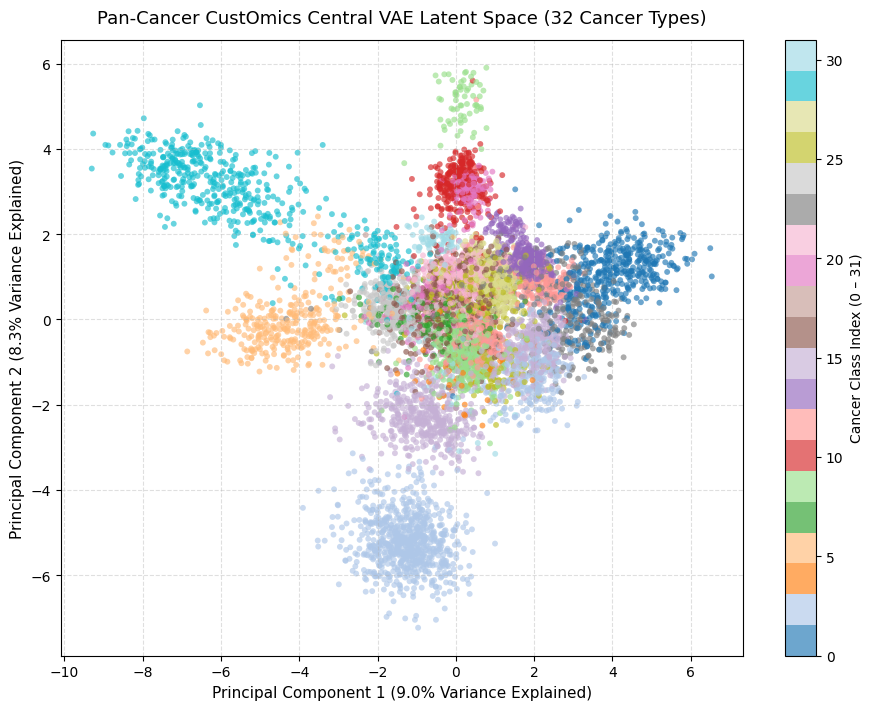

In [7]:
# 1. Load the saved latent embeddings from Fold 1 (8,314 samples x 64 latent dims)
latent_fold1 = np.load(os.path.join(ARTIFACT_DIR, "embeddings", "latent_fold_1.npy"))

# 2. Reduce 64D Central VAE latent representation down to 2D
pca = PCA(n_components=2)
z_2d = pca.fit_transform(latent_fold1)

# 3. Plot latent space colored by the 32 cancer lineages
plt.figure(figsize=(11, 8))
scatter = plt.scatter(
    z_2d[:, 0], 
    z_2d[:, 1], 
    c=y, 
    cmap="tab20", 
    alpha=0.65, 
    s=18, 
    edgecolors="none"
)

cbar = plt.colorbar(scatter, label="Cancer Class Index (0 – 31)")
plt.title("Pan-Cancer CustOmics Central VAE Latent Space (32 Cancer Types)", fontsize=13, pad=12)
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance Explained)", fontsize=11)
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance Explained)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.4)

# 4. Save high-resolution plot to disk
plot_path = os.path.join(ARTIFACT_DIR, "pancancer_latent_pca.png")
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
print(f"Plot successfully saved to: {plot_path}")

plt.show()